In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from neuralhydrology.evaluation import metrics
from neuralhydrology.nh_run import start_run, eval_run

In [2]:
if torch.cuda.is_available() or torch.backends.mps.is_available():
    start_run(config_file=Path("workshop_configs/GA_2basins_snowdcfe_mlp_static_params.yml"))

# fall back to CPU-only mode
else:
    start_run(config_file=Path("workshop_configs/GA_2basins_snowdcfe_mlp_static_params.yml"), gpu=-1)

2026-11-17 10:17:33,495: Logging to /home/adam/dev/hydrology-research/neuralhydrology-dcfe/examples/07-DCFE/runs/GA_2basins_snowdcfe_mlp_static_params_1711_101733/output.log initialized.
2026-11-17 10:17:33,496: ### Folder structure created at /home/adam/dev/hydrology-research/neuralhydrology-dcfe/examples/07-DCFE/runs/GA_2basins_snowdcfe_mlp_static_params_1711_101733
2026-11-17 10:17:33,497: ### Run configurations for GA_2basins_snowdcfe_mlp_static_params
2026-11-17 10:17:33,497: experiment_name: GA_2basins_snowdcfe_mlp_static_params
2026-11-17 10:17:33,498: train_basin_file: /home/adam/dev/hydrology-research/neuralhydrology-dcfe/examples/07-DCFE/GA_2basins.txt
2026-11-17 10:17:33,498: validation_basin_file: /home/adam/dev/hydrology-research/neuralhydrology-dcfe/examples/07-DCFE/GA_2basins.txt
2026-11-17 10:17:33,498: test_basin_file: /home/adam/dev/hydrology-research/neuralhydrology-dcfe/examples/07-DCFE/GA_2basins.txt
2026-11-17 10:17:33,499: train_start_date: 2000-10-01 00:00:00
20

In [ ]:
run_dir = Path("runs/GA_2basins_snowdcfe_mlp_static_params_1711_101733")
eval_run(run_dir, period="test")

FileNotFoundError: runs/GA_2basins_snowdcfe_operational_average_mlp_1711_100359/config.yml

load the run data

dict_keys(['02177000', '02349900'])


Text(0.5, 1.0, 'Test period - NSE 0.651')

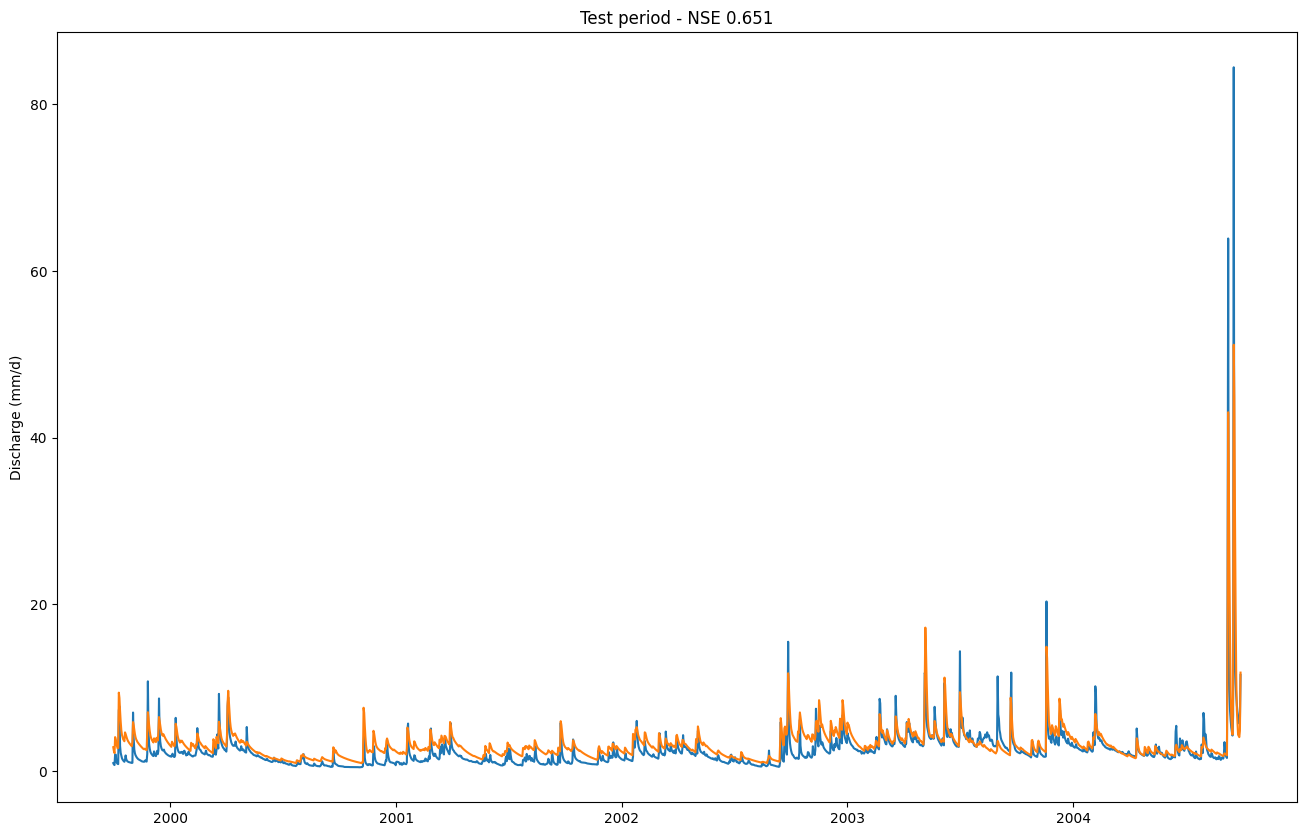

In [8]:
with open(run_dir / "test" / "model_epoch004" / "test_results.p", "rb") as fp:
    results = pickle.load(fp)
    
print(results.keys())

basin = '02177000' # the other option is '02349900'
# extract observations and simulations
qobs = results[basin]['1D']['xr']['QObs(mm/d)_obs']
qsim = results[basin]['1D']['xr']['QObs(mm/d)_sim']

fig, ax = plt.subplots(figsize=(16,10))
ax.plot(qobs['datetime'], qobs)
ax.plot(qsim['datetime'], qsim)
ax.set_ylabel("Discharge (mm/d)")
ax.set_title(f"Test period - NSE {results[basin]['1D']['NSE']:.3f}")

## Plotting the parameters

The parameters are predicted by an MLP from the static catchment attributes, so they are constant through time within a basin and differ only between basins.

In [ ]:
with open(run_dir / "test" / "model_epoch004" / "test_all_output.p", "rb") as fp:
    states_and_params = pickle.load(fp)

basins = [k for k in states_and_params.keys() if k != "datetime"]
param_dates = states_and_params["datetime"]
basin_colors = dict(zip(basins, ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple"]))


def plot_parameters(states_and_params: dict, basins: list[str]) -> tuple[plt.Figure, plt.Axes]:
    # Plots the MLP-predicted dCFE parameters through time for each basin.
    # Spinup period (dashed) gets the storages to physically meaningful magnitudes before the prediction period (solid).
    param_keys = list(states_and_params[basins[0]]["spinup_parameters"])

    fig, ax = plt.subplots(figsize=(16, 2.5 * len(param_keys)), nrows=len(param_keys), ncols=1, sharex=True)

    for i, param_i in enumerate(param_keys):
        show_label = (i == 0)
        for basin in basins:
            spinup = states_and_params[basin]["spinup_parameters"][param_i]
            prediction = states_and_params[basin]["prediction_parameters"][param_i]
            ax[i].plot(param_dates, spinup,
                       color=basin_colors[basin], linestyle='--', alpha=0.5,
                       label=f"{basin} Spinup" if show_label else None)
            ax[i].plot(param_dates, prediction,
                       color=basin_colors[basin], linestyle='-',
                       label=f"{basin} Prediction" if show_label else None)
        ax[i].set_ylabel(f"{param_i}")
        ax[i].grid()

    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=len(basins))
    fig.suptitle("MLP-predicted dCFE Parameters")
    plt.tight_layout(rect=[0, 0.02, 1, 0.94])
    return fig, ax


fig, ax = plot_parameters(states_and_params, basins)

In [ ]:
import numpy as np

# Since the parameters are static, a per-basin bar chart is a more compact view.
# One panel per parameter because each parameter lives on a different scale.
param_keys = list(states_and_params[basins[0]]["spinup_parameters"])
ncols = 4
nrows = int(np.ceil(len(param_keys) / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 3.5 * nrows))
axes = axes.flatten()

for i, param_i in enumerate(param_keys):
    values = [np.nanmean(states_and_params[b]["spinup_parameters"][param_i]) for b in basins]
    axes[i].bar(basins, values, color=[basin_colors[b] for b in basins])
    axes[i].set_title(param_i)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(axis="y")
    for j, v in enumerate(values):
        axes[i].annotate(f"{v:.3g}", (j, v), ha="center", va="bottom", fontsize=9)

for k in range(len(param_keys), len(axes)):
    axes[k].set_visible(False)

fig.suptitle("MLP-predicted dCFE Parameters per Basin")
plt.tight_layout()